## News visits analysis

This part focuses on how we can analyse the success of an article can be studied from the scope AIT. More precisly, we use AIT to try to find correlations beetween the content of the article (titles, bodies, etc) and the user-relative metrics (click, readtime, etc)

### BEFORE FIRST EXECUTION

Please download ebnerd_demo.zip at this adress : https://recsys.eb.dk/ and unzip it in this notebook directory

Please also note that the cell generating the results takes approximately one hour to run. Since a previous run has already generated the results and saved them in complexitys_48h.parquet, you can simply skip this cell and load the existing file instead.

### Imports

*There can be others. If the execution bugs, please add them ><*

In [ ]:
import pandas as pd

import time
from tqdm.auto import tqdm

import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

import statsmodels.formula.api as smf

### Dataset

We use EB-neRD.demo a dataset published by the danish newspaper Ekstra Bladet.
It notably contains archives of more than 10 000 articles, more than half of them with user-relative metrics (total_inviews', 'total_pageviews', 'total_read_time')

In [ ]:
# pip install pandas pyarrow
art = pd.read_parquet("articles.parquet")
print(art.shape)
print(art.columns.tolist())
art.head()

(11777, 21)
['article_id', 'title', 'subtitle', 'last_modified_time', 'premium', 'body', 'published_time', 'image_ids', 'article_type', 'url', 'ner_clusters', 'entity_groups', 'topics', 'category', 'subcategory', 'category_str', 'total_inviews', 'total_pageviews', 'total_read_time', 'sentiment_score', 'sentiment_label']


,article_id,title,subtitle,last_modified_time,premium,body,published_time,image_ids,article_type,url,...,entity_groups,topics,category,subcategory,category_str,total_inviews,total_pageviews,total_read_time,sentiment_score,sentiment_label
0,3037230,Ishockey-spiller: Jeg troede jeg skulle dø,ISHOCKEY: Ishockey-spilleren Sebastian Harts h...,2023-06-29 06:20:57,False,Ambitionerne om at komme til USA og spille ish...,2003-08-28 08:55:00,None,article_default,https://ekstrabladet.dk/sport/anden_sport/isho...,...,[],"[Kriminalitet, Kendt, Sport, Katastrofe, Mindr...",142,"[327, 334]",sport,NaN,NaN,NaN,0.9752,Negative
1,3044020,Prins Harry tvunget til dna-test,Hoffet tvang Prins Harry til at tage dna-test ...,2023-06-29 06:21:16,False,Den britiske tabloidavis The Sun fortsætter me...,2005-06-29 08:47:00,"[3097307, 3097197, 3104927]",article_default,https://ekstrabladet.dk/underholdning/udlandke...,...,"[PER, PER]","[Kriminalitet, Kendt, Underholdning, Personfar...",414,[432],underholdning,NaN,NaN,NaN,0.7084,Negative
2,3057622,Rådden kørsel på blå plader,Kan ikke straffes: Udenlandske diplomater i Da...,2023-06-29 06:21:24,False,Slingrende spritkørsel. Grove overtrædelser af...,2005-10-10 07:20:00,[3047102],article_default,https://ekstrabladet.dk/nyheder/samfund/articl...,...,[],"[Kriminalitet, Transportmiddel, Bil]",118,[133],nyheder,NaN,NaN,NaN,0.9236,Negative
3,3073151,Mærsk-arvinger i livsfare,FANGET I FLODBØLGEN: Skibsrederens oldebørn må...,2023-06-29 06:21:38,False,To oldebørn af skibsreder Mærsk McKinney Mølle...,2005-01-04 06:59:00,"[3067474, 3067478, 3153705]",article_default,https://ekstrabladet.dk/nyheder/samfund/articl...,...,[],"[Erhverv, Privat virksomhed, Livsstil, Familie...",118,[133],nyheder,NaN,NaN,NaN,0.9945,Negative
4,3193383,Skød svigersøn gennem babydyne,44-årig kvinde tiltalt for drab på ekssvigersø...,2023-06-29 06:22:57,False,En 44-årig mormor blev i dag fremstillet i et ...,2003-09-15 15:30:00,None,article_default,https://ekstrabladet.dk/krimi/article3193383.ece,...,[],"[Kriminalitet, Personfarlig kriminalitet]",140,[],krimi,NaN,NaN,NaN,0.9966,Negative



We now reformate the dataset and split it into 2 categories:
- full_corpus : contains every article (to encode environment)
- toStudy_corpus : contains only the articles that will be studied statistically

In [ ]:
#FULL CORPUS:
cols = ["article_id", "title", "subtitle", "premium", "body", "category_str",
        "published_time", "total_inviews", "total_pageviews", "total_read_time"]
full_corpus = (
    art[cols]
    .copy()
    .assign(published_time=lambda d: pd.to_datetime(d["published_time"]))
    .sort_values("published_time")
    .reset_index(drop=True)
)
# TOSTUDY_CORPUS
toStudy_corpus=  full_corpus.copy()
#       We only keep lines which usage can be analyse
toStudy_corpus = toStudy_corpus.dropna(subset=["total_inviews", "total_pageviews", "total_read_time"])
toStudy_corpus = toStudy_corpus[toStudy_corpus["total_inviews"] > 0]
toStudy_corpus = toStudy_corpus[toStudy_corpus["body"].str.len() > 500]
toStudy_corpus = toStudy_corpus[~toStudy_corpus["premium"]]
#       We also add interesting metrics
toStudy_corpus["ctr"] = toStudy_corpus["total_pageviews"] / toStudy_corpus["total_inviews"]             # Is the article appeling? (people click when they see it)
toStudy_corpus["read_per_view"] = toStudy_corpus["total_read_time"] / toStudy_corpus["total_pageviews"]  # Does people stick to the article?
toStudy_corpus["body_len"] = toStudy_corpus["body"].str.len()

print(len(full_corpus))
print(len(toStudy_corpus))


11777
6322


### Complexities computation

We want now to create functions to compute complexities. For clarity sake and ease of use, we create a python class that encapsulates the corpus operations.

In [ ]:
FILTERS = [{"id": lzma.FILTER_LZMA2, "preset": 9, "dict_size": 64 * 2**20}]  # Window 64 Mo

def complexity(text: str) -> int:
    return len(lzma.compress(text.encode("utf-8"), format=lzma.FORMAT_RAW, filters=FILTERS))


class NewsCorpus:
    def __init__(self, df):
        assert df["article_id"].is_unique
        self.df = df  #We put the date in datetime format and we make sure the articles are sorted by datetime
        self.id2date = self.df.set_index("article_id")["published_time"] 
        self.id2pos = pd.Series(self.df.index, index=self.df["article_id"])
        self.id2body = self.df.set_index("article_id")["body"]
        self.id2title = self.df.set_index("article_id")["title"]
        self._t = self.df["published_time"].values

    def date(self, article_id):
        return self.id2date[article_id]

    def body(self, article_id):
        return self.id2body[article_id]

    def title(self, article_id):
        return self.id2title[article_id]

    def env(self, article_id, hours=48):
        """
        Extract the environment of an article, that is to say the articles that were published in the h hours before the goven article.
        
        The "hours" parameter can be a number or None. In the latter case, all the precedent article will be in the environment
        """
        i = self.id2pos[article_id] 

        if hours is None:
            return self.df.iloc[:i] # all articles before
        else:
            lo = self._t.searchsorted(self._t[i] - pd.Timedelta(hours=hours))
            return self.df.iloc[lo:i]


def complexities(corpus, article_id, hours=48):
    body= corpus.body(article_id)
    title = corpus.title(article_id)
    
    dataset_env = corpus.env(article_id, hours)
    str_env = " ".join(dataset_env["body"].tolist())
    complexity_env = complexity(str_env) #USed to compute C_cond

    C_self= complexity(body)
    C_cond= complexity(str_env + " " +body) - complexity_env

    C_self_title=complexity(title)
    C_cond_title=complexity(str_env + " " +title) - complexity_env
    return {"article_id": article_id,
        "env_n": len(dataset_env), "env_chars": len(str_env),
        "c_self": C_self, "c_cond": C_cond,
        "novelty": C_cond / C_self if C_self else float("nan"),
        "c_self_title": C_self_title, "c_cond_title": C_cond_title,
        "novelty_title": C_cond_title / C_self_title if C_self_title else float("nan")
        }



We can use this new structure on our full_corpus and then test the complexity on the first article

In [ ]:
corpus=  NewsCorpus(full_corpus)
first_article_id = toStudy_corpus["article_id"].iloc[0]
t0 = time.time(); print( complexities(corpus, first_article_id) ); print(time.time() - t0, "s")


{'article_id': 9637298, 'env_n': 26, 'env_chars': 52953, 'c_self': 1332, 'c_cond': 912, 'novelty': 0.6846846846846847, 'c_self_title': 24, 'c_cond_title': 9, 'novelty_title': 0.375}
0.11123085021972656 s


We can now generate our results.

In [ ]:
res = pd.DataFrame([complexities(corpus, a, hours=48) for a in tqdm(toStudy_corpus["article_id"])])
res.to_parquet("complexities_48h.parquet")   # sauvegarde pour ne pas recalculer

  0%|          | 0/6322 [00:00<?, ?it/s]

### Results analysis

First let's concatenate our results with the rest of the dataset.

In [ ]:
res = pd.read_parquet("complexities_48h.parquet")
df = res.merge(toStudy_corpus, on="article_id", how="left")
print(df.shape)

(6322, 21)


#### Metrics analysis

First, we  try to understand how the text-metrics we have calculated are corrolated to the text and the environment themselves. (Typically, how having a big environment or a big body influence the complexities)

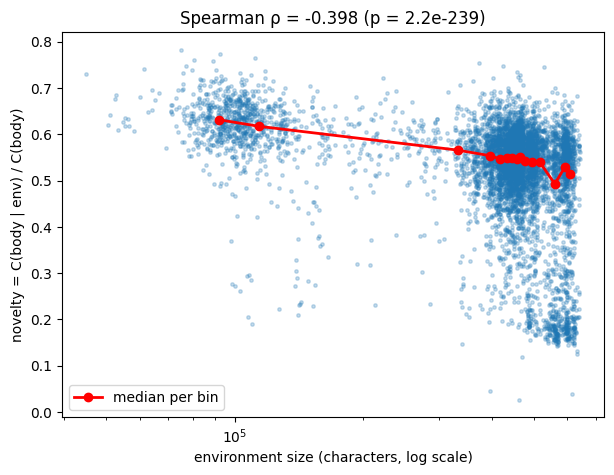

In [ ]:
# Novelty and size of the environment

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["env_chars"], df["novelty"], s=6, alpha=0.25)

med1 = df.groupby(pd.qcut(df["env_chars"], 15, duplicates="drop"), observed=True)[["env_chars", "novelty"]].median()
ax.plot(med1["env_chars"], med1["novelty"], color="red", lw=2, marker="o", label="median per bin")

rho1, p1 = stats.spearmanr(df["env_chars"], df["novelty"])
ax.set_xscale("log")
ax.set_xlabel("environment size (characters, log scale)")
ax.set_ylabel("novelty = C(body | env) / C(body)")
ax.set_title(f"Spearman ρ = {rho1:.3f} (p = {p1:.1e})")
ax.legend()
plt.show()

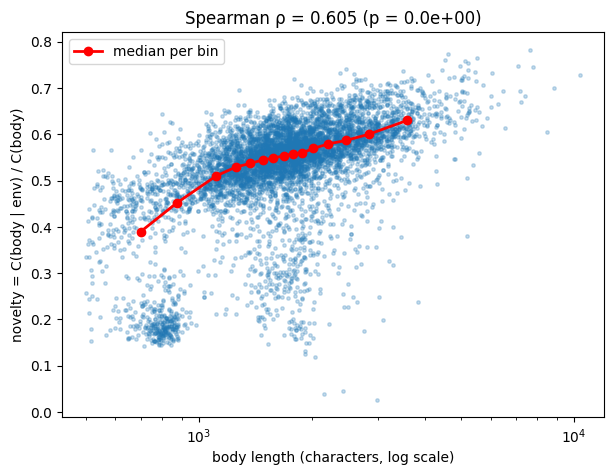

In [ ]:
# Novelty and size of the article

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["body_len"], df["novelty"], s=6, alpha=0.25)

med2 = df.groupby(pd.qcut(df["body_len"], 15, duplicates="drop"), observed=True)[["body_len", "novelty"]].median()
ax.plot(med2["body_len"], med2["novelty"], color="red", lw=2, marker="o", label="median per bin")

rho2, p2 = stats.spearmanr(df["body_len"], df["novelty"])
ax.set_xscale("log")
ax.set_xlabel("body length (characters, log scale)")
ax.set_ylabel("novelty = C(body | env) / C(body)")
ax.set_title(f"Spearman ρ = {rho2:.3f} (p = {p2:.1e})")
ax.legend()
plt.show()

As we could have guessed, we observe 2 phenomena
- The bigger the environment, the less novelty. 
- The smaller the text, the more novelty.

 However, these effects do not necessary have to be compensated as they also impacts the reader.
 - If there is a lot of article in a given span of time, the user is less likely to spend attention on one particular article.
 - If something is short, it is less redundant and mecanically contains more novalty. 

#### First Hypothesis : The articles most visited are those with the most novelty in the title

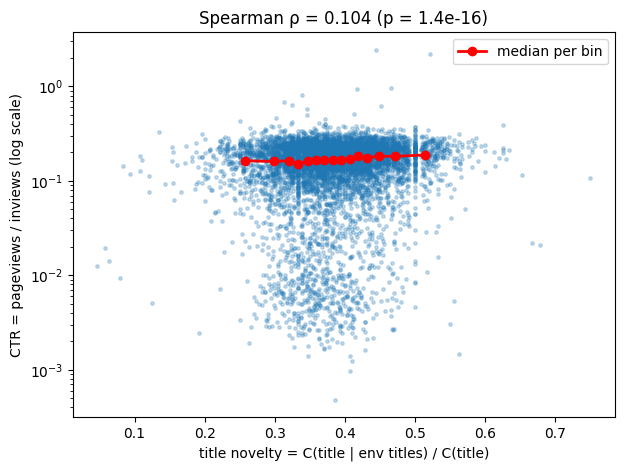

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty_title"], df["ctr"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty_title"], 15, duplicates="drop"), observed=True)[["novelty_title", "ctr"]].median()
ax.plot(med["novelty_title"], med["ctr"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty_title"], df["ctr"])
ax.set_yscale("log")
ax.set_xlabel("title novelty = C(title | env titles) / C(title)")
ax.set_ylabel("CTR = pageviews / inviews (log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.legend()
plt.show()

In [ ]:
df["title_len"] = df["title"].str.len()
smf.ols("np.log(ctr) ~ novelty_title + np.log(title_len) + np.log(env_chars) + C(category_str)",
        data=df).fit().summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:            np.log(ctr)   R-squared:                       0.723
Model:                            OLS   Adj. R-squared:                  0.722
Method:                 Least Squares   F-statistic:                     913.9
Date:                Sat, 07 Nov 2026   Prob (F-statistic):               0.00
Time:                        08:23:07   Log-Likelihood:                -5153.0
No. Observations:                6322   AIC:                         1.034e+04
Df Residuals:                    6303   BIC:                         1.047e+04
Df Model:                          18                                         
Covariance Type:            nonrobust                                         
=====================================================================================================
                                        coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------------------
Intercept                            -4.0852      0.211    -19.333      0.000      -4.499      -3.671
C(category_str)[T.bibliotek]          2.1839      0.317      6.890      0.000       1.563       2.805
C(category_str)[T.biler]              2.2600      0.140     16.176      0.000       1.986       2.534
C(category_str)[T.ferie]              2.1136      0.109     19.350      0.000       1.900       2.328
C(category_str)[T.forbrug]            2.7695      0.055     50.358      0.000       2.662       2.877
C(category_str)[T.haandvaerkeren]     0.4716      0.110      4.275      0.000       0.255       0.688
C(category_str)[T.incoming]          -1.9505      0.548     -3.559      0.000      -3.025      -0.876
C(category_str)[T.krimi]              3.1453      0.032     98.605      0.000       3.083       3.208
C(category_str)[T.musik]              3.1446      0.055     56.833      0.000       3.036       3.253
C(category_str)[T.nationen]           3.0254      0.046     66.077      0.000       2.936       3.115
C(category_str)[T.nyheder]            2.9577      0.027    109.364      0.000       2.905       3.011
C(category_str)[T.opinionen]          0.7667      0.126      6.098      0.000       0.520       1.013
C(category_str)[T.penge]              3.1588      0.055     57.366      0.000       3.051       3.267
C(category_str)[T.sex_og_samliv]      1.9653      0.144     13.644      0.000       1.683       2.248
C(category_str)[T.sport]              2.6893      0.028     97.016      0.000       2.635       2.744
C(category_str)[T.underholdning]      3.0526      0.031     98.660      0.000       2.992       3.113
novelty_title                         0.3645      0.104      3.494      0.000       0.160       0.569
np.log(title_len)                    -0.0511      0.023     -2.251      0.024      -0.096      -0.007
np.log(env_chars)                    -0.0485      0.013     -3.647      0.000      -0.075      -0.022
==============================================================================
Omnibus:                     1342.812   Durbin-Watson:                   1.950
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             5872.393
Skew:                          -0.975   Prob(JB):                         0.00
Kurtosis:                       7.300   Cond. No.                     1.07e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.07e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

#### Second Hypothesis : The articles that retains the readers the most are those with the most novelty in their body.

  8%|▊         | 519/6322 [1:18:25<14:36:47,  9.07s/it]


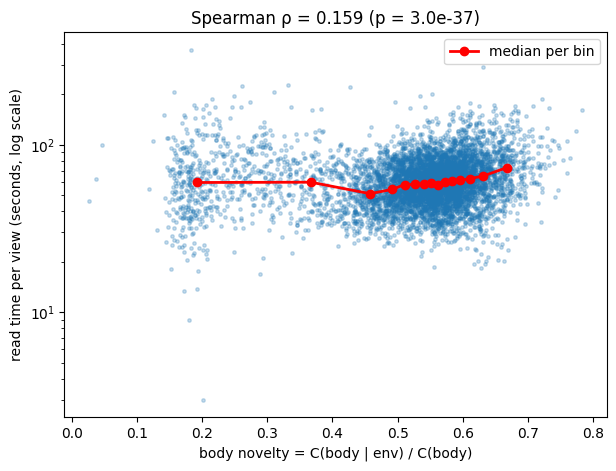

In [ ]:
# --- Plot: read time per view vs body novelty ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty"], df["read_per_view"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty"], 15, duplicates="drop"), observed=True)[["novelty", "read_per_view"]].median()
ax.plot(med["novelty"], med["read_per_view"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty"], df["read_per_view"])
ax.set_yscale("log")
ax.set_xlabel("body novelty = C(body | env) / C(body)")
ax.set_ylabel("read time per view (seconds, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.legend()
plt.show()

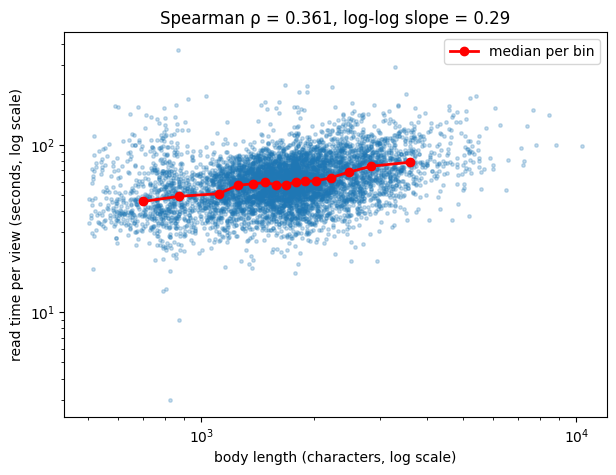

In [ ]:
# --- Plot: read time per view vs body length ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["body_len"], df["read_per_view"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["body_len"], 15, duplicates="drop"), observed=True)[["body_len", "read_per_view"]].median()
ax.plot(med["body_len"], med["read_per_view"], color="red", lw=2, marker="o", label="median per bin")

# log-log slope: 1 = read time proportional to length, <1 = people read proportionally less of long articles
slope, intercept = np.polyfit(np.log(df["body_len"]), np.log(df["read_per_view"]), 1)

rho, p = stats.spearmanr(df["body_len"], df["read_per_view"])
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xlabel("body length (characters, log scale)")
ax.set_ylabel("read time per view (seconds, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f}, log-log slope = {slope:.2f}")
ax.legend()
plt.show()

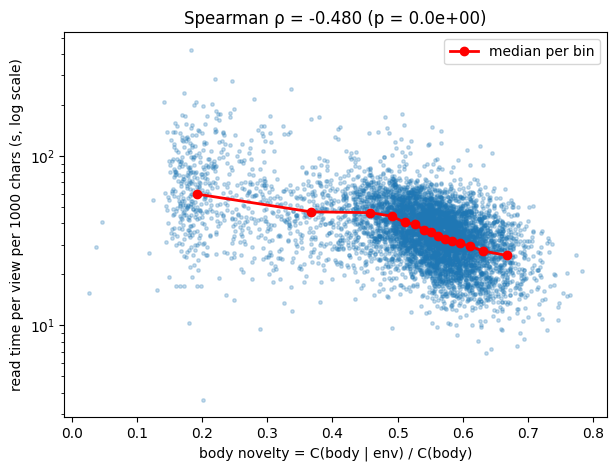

In [ ]:
# --- Plot: read time per view per 1000 characters vs body novelty ---
df["read_per_kchar"] = df["read_per_view"] / (df["body_len"] / 1000)

fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty"], df["read_per_kchar"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty"], 15, duplicates="drop"), observed=True)[["novelty", "read_per_kchar"]].median()
ax.plot(med["novelty"], med["read_per_kchar"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty"], df["read_per_kchar"])
ax.set_yscale("log")
ax.set_xlabel("body novelty = C(body | env) / C(body)")
ax.set_ylabel("read time per view per 1000 chars (s, log scale)")
ax.set_title(f"Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.legend()
plt.show()

In [ ]:
x = np.log(df["body_len"])

# length-adjusted read time (residual of the log-log fit)
slope, intercept = np.polyfit(x, np.log(df["read_per_view"]), 1)
df["read_adj"] = np.log(df["read_per_view"]) - (intercept + slope * x)

# length-adjusted novelty
s_n, i_n = np.polyfit(x, df["novelty"], 1)
df["novelty_adj"] = df["novelty"] - (i_n + s_n * x)

print(stats.spearmanr(df["body_len"], df["read_adj"]))   # check: should be ~0
print(stats.spearmanr(df["novelty_adj"], df["read_adj"]))  # the partial correlation you want

SignificanceResult(statistic=0.017481925736424115, pvalue=0.16457843009494952)
SignificanceResult(statistic=-0.11279916644568065, pvalue=2.3468118244197904e-19)


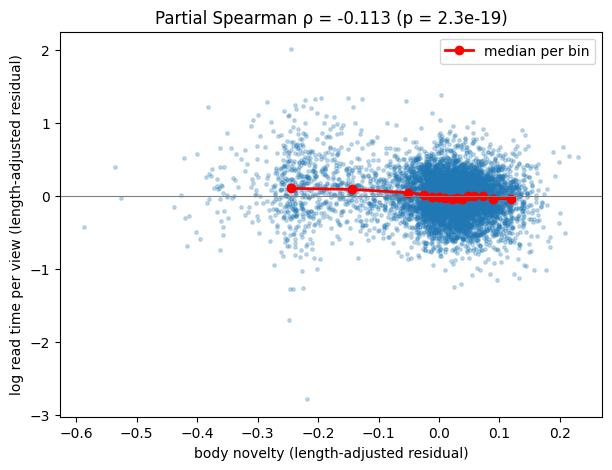

In [ ]:
# --- Plot: length-adjusted read time vs length-adjusted novelty ---
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(df["novelty_adj"], df["read_adj"], s=6, alpha=0.25)

med = df.groupby(pd.qcut(df["novelty_adj"], 15, duplicates="drop"), observed=True)[["novelty_adj", "read_adj"]].median()
ax.plot(med["novelty_adj"], med["read_adj"], color="red", lw=2, marker="o", label="median per bin")

rho, p = stats.spearmanr(df["novelty_adj"], df["read_adj"])
ax.set_xlabel("body novelty (length-adjusted residual)")
ax.set_ylabel("log read time per view (length-adjusted residual)")
ax.set_title(f"Partial Spearman ρ = {rho:.3f} (p = {p:.1e})")
ax.axhline(0, color="gray", lw=0.8)
ax.legend()
plt.show()

In [ ]:
!ls